# Day5 Task3 - Five Visualisations

## Employee Salary Data Visualisation

This notebook creates five visualisations using the cleaned employee dataset.
The charts help understand salary distribution, department comparisons and salary patterns.
All figures are saved in the reports/figures folder.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# Load cleaned employee data
df = pd.read_csv("../../data/clean_data.csv")

# Create output folder
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Consistent colour scheme
primary_color = "#4472C4"
secondary_color = "#ED7D31"
third_color = "#70AD47"
fourth_color = "#A5A5A5"
fifth_color = "#5B9BD5"

department_colors = {
    "Finance": primary_color,
    "HR": secondary_color,
    "IT": third_color,
    "Sales": fourth_color
}

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (8, 6)


,id,name,department,salary,city,salary_outlier
0,1,Arun,Sales,30000.0,Chennai,False
1,2,Priya,Hr,60000.0,Chennai,False
2,3,Rahul,It,60000.0,Bangalore,False
3,4,Divya,It,75000.0,Chennai,False
4,5,Karthik,Finance,90000.0,Chennai,False


## 1. Bar Chart - Average Salary by Department

This chart compares the average employee salary across departments.

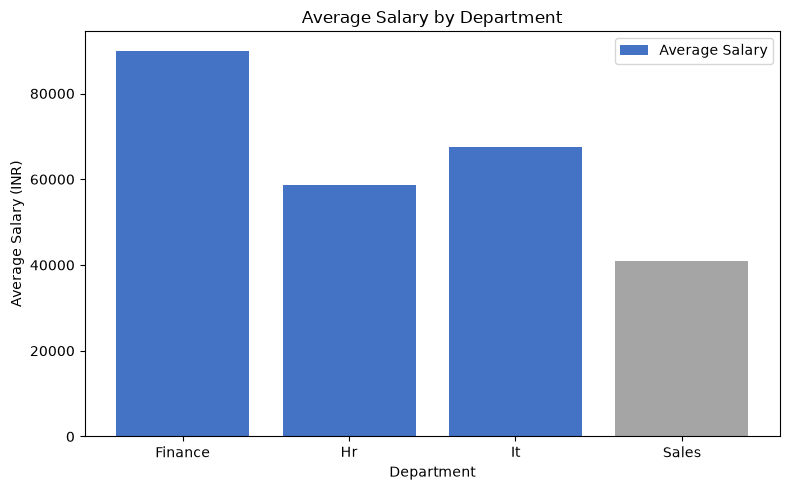

In [3]:
department_salary = df.groupby("department", observed=True)["salary"].mean()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    department_salary.index,
    department_salary.values,
    color=[department_colors.get(dept, primary_color)
           for dept in department_salary.index]
)

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary (INR)")
plt.legend([bars[0]], ["Average Salary"], loc="best")
plt.tight_layout()

plt.savefig(figures_dir / "01_bar_chart.png", dpi=300)
plt.show()

**Insight:** Finance has the highest average salary, while Sales has the lowest average salary among the departments.

## 2. Histogram - Salary Distribution

This histogram shows the distribution of employee salaries.

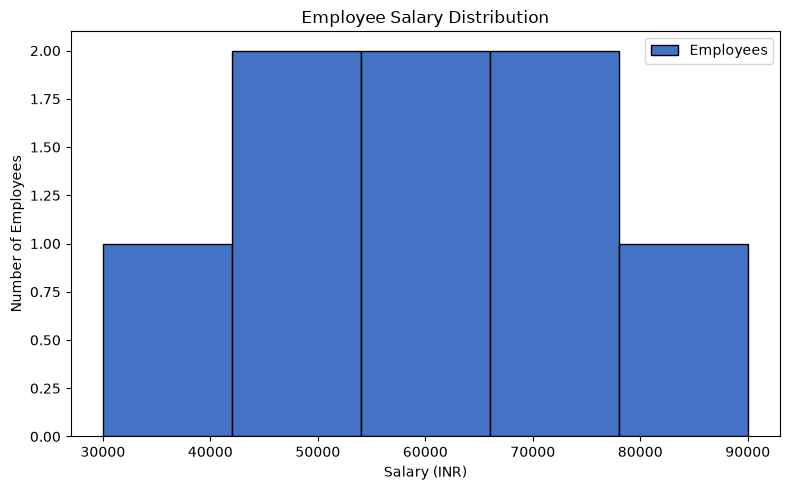

In [4]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["salary"],
    bins=5,
    color=primary_color,
    edgecolor="black",
    label="Employees"
)

plt.title("Employee Salary Distribution")
plt.xlabel("Salary (INR)")
plt.ylabel("Number of Employees")
plt.legend()
plt.tight_layout()

plt.savefig(figures_dir / "02_histogram.png", dpi=300)
plt.show()

**Insight:** The histogram shows how employee salaries are distributed across different salary ranges.

## 3. Scatter Plot - Employee ID vs Salary

This scatter plot displays salary values for individual employee IDs.
Employee ID is used only to distinguish employees, not as a meaningful business variable.

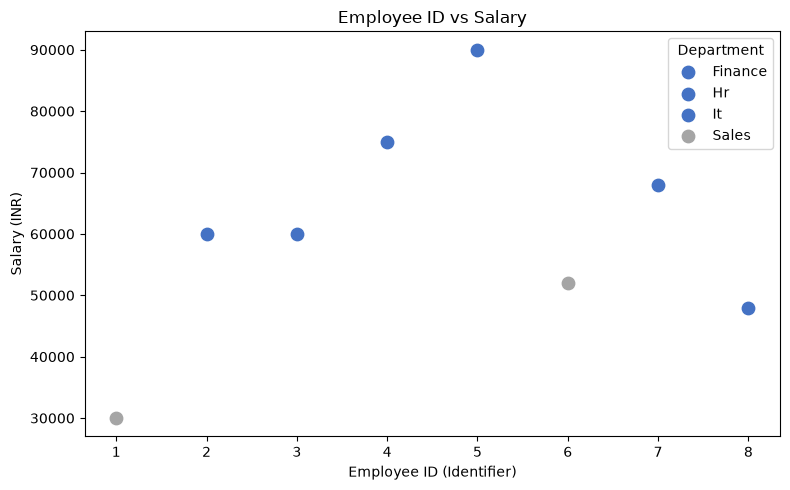

In [5]:
plt.figure(figsize=(8, 5))

for department, group in df.groupby("department", observed=True):
    plt.scatter(
        group["id"],
        group["salary"],
        color=department_colors.get(department, primary_color),
        label=department,
        s=80
    )

plt.title("Employee ID vs Salary")
plt.xlabel("Employee ID (Identifier)")
plt.ylabel("Salary (INR)")
plt.legend(title="Department")
plt.tight_layout()

plt.savefig(figures_dir / "03_scatter_plot.png", dpi=300)
plt.show()

**Insight:** The scatter plot displays individual salary values and their variation across employees and departments, but employee ID does not indicate a meaningful salary relationship.

## 4. Line Chart - Sorted Employee Salaries

Employee salaries are sorted from lowest to highest to visualize the salary range and progression.
This is a sorted comparison, not a time-based trend.

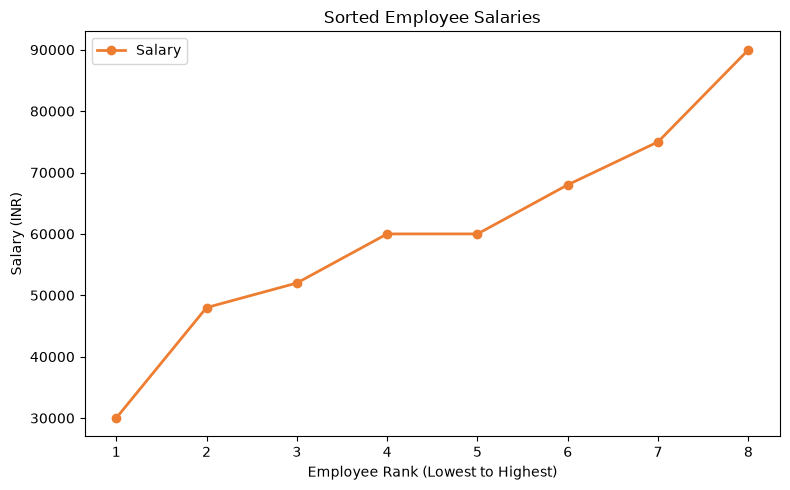

In [6]:
sorted_salaries = df["salary"].sort_values().reset_index(drop=True)

plt.figure(figsize=(8, 5))

plt.plot(
    sorted_salaries.index + 1,
    sorted_salaries.values,
    marker="o",
    color=secondary_color,
    linewidth=2,
    label="Salary"
)

plt.title("Sorted Employee Salaries")
plt.xlabel("Employee Rank (Lowest to Highest)")
plt.ylabel("Salary (INR)")
plt.legend()
plt.tight_layout()

plt.savefig(figures_dir / "04_line_chart.png", dpi=300)
plt.show()

**Insight:** Sorting salaries from lowest to highest makes the salary range and differences between employees easier to observe.

## 5. Box Plot - Salary by Department

This box plot compares salary distribution, median salary and spread across departments.

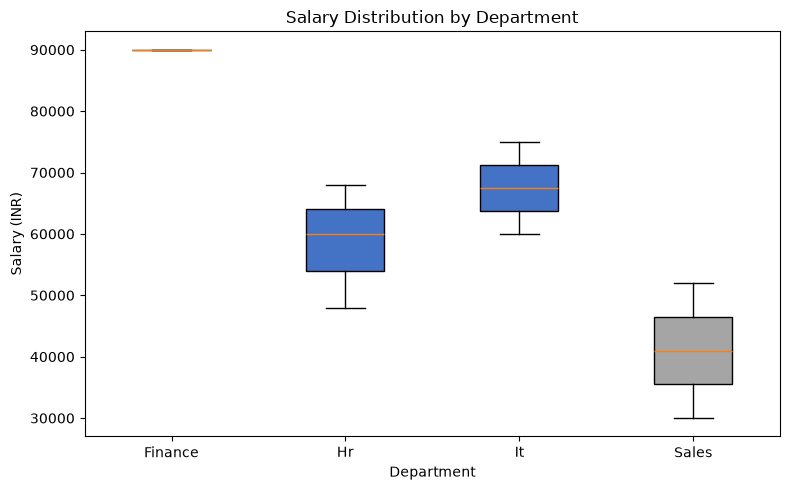

In [9]:
departments = sorted(df["department"].unique())

salary_groups = [
    df.loc[df["department"] == dept, "salary"]
    for dept in departments
]

box_colors = [
    department_colors.get(dept, primary_color)
    for dept in departments
]

plt.figure(figsize=(8, 5))

box = plt.boxplot(
    salary_groups,
    tick_labels=departments,
    patch_artist=True
)

for patch, color in zip(box["boxes"], box_colors):
    patch.set_facecolor(color)

plt.title("Salary Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Salary (INR)")
plt.tight_layout()

plt.savefig(figures_dir / "05_box_plot.png", dpi=300)
plt.show()

**Insight:** The box plot helps compare the salary spread and median salary across departments, although departments with very few employees have limited distribution information.

In [10]:
# List saved figure files
saved_figures = list(figures_dir.glob("*.png"))

print("Total figures saved:", len(saved_figures))

for figure in saved_figures:
    print(figure.name)

Total figures saved: 5
01_bar_chart.png
02_histogram.png
03_scatter_plot.png
04_line_chart.png
05_box_plot.png
